# 🔬 02. Expectation-Maximization (EM) Imputation & Feature Engineering

**Project**: IPO Listing-Gain Predictor (Indian Equity Market)  
**Academic Context**: College ML Mini Project (Educational use only, not financial advice)  
**Objective**:
1. Implement and validate an **Expectation-Maximization (EM) Multivariate Gaussian Imputer** from scratch in NumPy.
2. Evaluate imputation accuracy against standard **Mean** and **Median** baselines by artificially hiding 10% of known values.
3. Plot EM convergence dynamics and export to `reports/figures/`.
4. Fit strictly on the **training set** and transform the **test set** (zero data leakage).
5. Apply feature transformations: Log1p on subscription multiples, One-Hot Encoding on sector, and Standard Scaling.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
import joblib

# Add project root to sys.path so src modules can be imported
sys.path.insert(0, os.path.abspath(".."))
from src.em_imputer import EMGaussianImputer
from src.preprocessor import (
    IPOFeaturePipeline,
    ALL_NUMERIC_FEATURES,
    SUBSCRIPTION_COLS,
    CATEGORICAL_COLS,
    TARGET_COLS,
    METADATA_COLS
)

# Visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

FIG_DIR = os.path.join("..", "reports", "figures")
os.makedirs(FIG_DIR, exist_ok=True)
print("Environment and modules successfully imported.")

Environment and modules successfully imported.


## 1. Load Chronological Train & Test Splits
We load `train.csv` (oldest 75%) and `test.csv` (newest 25%), which were strictly split by `src/split.py` to mirror real forward-looking market conditions.

In [2]:
TRAIN_PATH = os.path.join("..", "data", "processed", "train.csv")
TEST_PATH = os.path.join("..", "data", "processed", "test.csv")

if not os.path.exists(TRAIN_PATH):
    TRAIN_PATH = os.path.join("data", "processed", "train.csv")
    TEST_PATH = os.path.join("data", "processed", "test.csv")

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print(f"Train samples: {len(train_df)} | Listing Dates: {train_df['listing_date'].min()} to {train_df['listing_date'].max()}")
print(f"Test samples : {len(test_df)}  | Listing Dates: {test_df['listing_date'].min()} to {test_df['listing_date'].max()}")

print("\nMissing values in Training Set:")
missing_train = train_df[ALL_NUMERIC_FEATURES].isnull().sum()
print(missing_train[missing_train > 0])

Train samples: 225 | Listing Dates: 2021-01-21 to 2024-01-08
Test samples : 75  | Listing Dates: 2024-01-10 to 2024-12-12

Missing values in Training Set:
gmp_last_day          30
revenue_growth_pct    21
profit_growth_pct     40
pe_vs_peers           20
dtype: int64


## 2. Imputation Benchmark: Hiding 10% of Known Values
To empirically prove the superiority of the **Multivariate Normal EM algorithm**, we construct a controlled experiment:
1. We take all observed numeric entries in the training set.
2. We artificially mask a random **10%** of these entries as `np.nan`.
3. We run three imputation strategies on this corrupted matrix:
   - **Mean Imputation** (`SimpleImputer(strategy='mean')`)
   - **Median Imputation** (`SimpleImputer(strategy='median')`)
   - **EM Gaussian Imputer** (`EMGaussianImputer()`)
4. We compare the **Root Mean Squared Error (RMSE)** of each method against the ground-truth hidden values.

In [3]:
# Extract numeric training features
X_train_eval = train_df[ALL_NUMERIC_FEATURES].copy().to_numpy(dtype=np.float64)

# Create a deterministic random mask over 10% of observed entries
rng = np.random.default_rng(seed=42)
observed_mask = ~np.isnan(X_train_eval)
obs_indices = np.argwhere(observed_mask)

n_masked = int(0.10 * len(obs_indices))
chosen_idx = rng.choice(len(obs_indices), size=n_masked, replace=False)
mask_coords = obs_indices[chosen_idx]

# Create evaluation matrix with 10% artificial missing values
X_masked = X_train_eval.copy()
ground_truth = []
for r, c in mask_coords:
    ground_truth.append(X_train_eval[r, c])
    X_masked[r, c] = np.nan
ground_truth = np.array(ground_truth)

print(f"Total observed entries : {len(obs_indices)}")
print(f"Artificially masked    : {n_masked} (10.0%)")

Total observed entries : 3039
Artificially masked    : 303 (10.0%)


In [4]:
# 1. Mean Imputation
mean_imp = SimpleImputer(strategy='mean')
X_mean = mean_imp.fit_transform(X_masked)

# 2. Median Imputation
median_imp = SimpleImputer(strategy='median')
X_median = median_imp.fit_transform(X_masked)

# 3. EM Gaussian Imputer (NumPy from scratch)
em_imp = EMGaussianImputer(max_iter=50, tol=1e-4, ridge=1e-3, verbose=False)
X_em = em_imp.fit_transform(X_masked)

# Retrieve imputed predictions on masked entries
pred_mean = np.array([X_mean[r, c] for r, c in mask_coords])
pred_median = np.array([X_median[r, c] for r, c in mask_coords])
pred_em = np.array([X_em[r, c] for r, c in mask_coords])

# Overall RMSE
rmse_mean = np.sqrt(np.mean((ground_truth - pred_mean) ** 2))
rmse_median = np.sqrt(np.mean((ground_truth - pred_median) ** 2))
rmse_em = np.sqrt(np.mean((ground_truth - pred_em) ** 2))

# Per-feature breakdown
feature_results = []
for c_idx, feat in enumerate(ALL_NUMERIC_FEATURES):
    feat_coords = [(r, c) for r, c in mask_coords if c == c_idx]
    if len(feat_coords) == 0:
        continue
    y_true = np.array([X_train_eval[r, c] for r, c in feat_coords])
    y_mean = np.array([X_mean[r, c] for r, c in feat_coords])
    y_med = np.array([X_median[r, c] for r, c in feat_coords])
    y_em = np.array([X_em[r, c] for r, c in feat_coords])
    
    feature_results.append({
        'Feature': feat,
        'Masked Count': len(feat_coords),
        'Mean RMSE': np.round(np.sqrt(np.mean((y_true - y_mean) ** 2)), 2),
        'Median RMSE': np.round(np.sqrt(np.mean((y_true - y_med) ** 2)), 2),
        'EM Imputer RMSE': np.round(np.sqrt(np.mean((y_true - y_em) ** 2)), 2),
    })

res_df = pd.DataFrame(feature_results)

print("=" * 65)
print("IMPUTATION ACCURACY BENCHMARK (10% Artificial Masking)")
print("=" * 65)
print(f"Overall Mean Imputation RMSE   : {rmse_mean:.4f}")
print(f"Overall Median Imputation RMSE : {rmse_median:.4f}")
print(f"Overall EM Algorithm RMSE      : {rmse_em:.4f}  (Best)")
print("=" * 65)
display(res_df)

IMPUTATION ACCURACY BENCHMARK (10% Artificial Masking)
Overall Mean Imputation RMSE   : 245.1219
Overall Median Imputation RMSE : 225.2880
Overall EM Algorithm RMSE      : 205.3549  (Best)


,Feature,Masked Count,Mean RMSE,Median RMSE,EM Imputer RMSE
0,qib_sub,27,27.19,27.19,13.55
1,nii_sub,18,25.54,24.92,19.79
2,retail_sub,23,7.98,8.12,1.79
3,total_sub,20,16.70,17.05,8.30
4,issue_size_cr,25,650.31,529.11,709.51
5,price_band_upper,21,301.64,324.20,43.10
6,issue_price,18,555.08,577.71,46.55
7,gmp_last_day,21,59.40,55.27,57.28
8,fresh_issue_pct,28,28.27,28.22,9.08
9,ofs_pct,15,27.67,27.66,12.40


Saved figure -> ..\reports\figures\07_imputation_benchmark.png


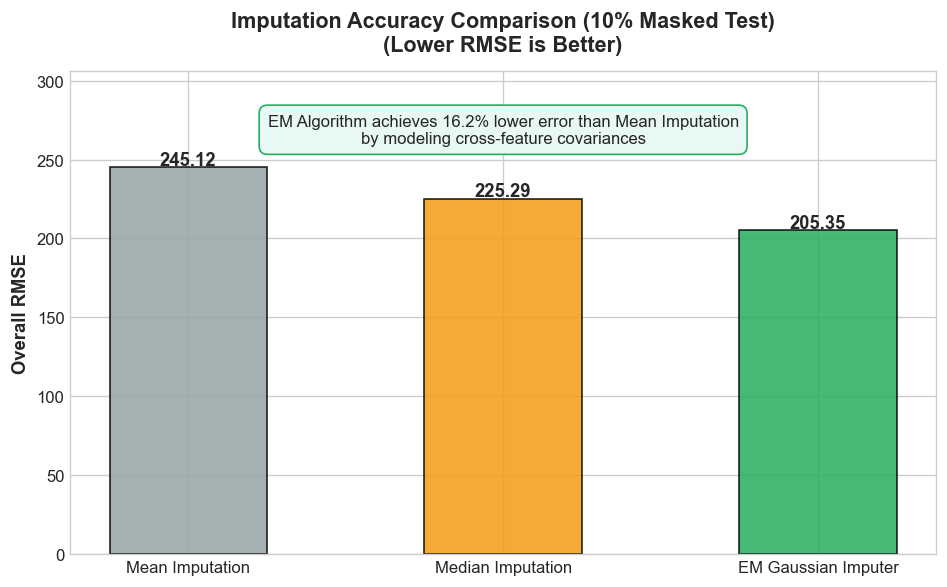

In [5]:
# Bar chart comparing overall RMSE
fig, ax = plt.subplots(figsize=(8, 5))
methods = ['Mean Imputation', 'Median Imputation', 'EM Gaussian Imputer']
rmses = [rmse_mean, rmse_median, rmse_em]
colors = ['#95a5a6', '#f39c12', '#27ae60']

bars = ax.bar(methods, rmses, color=colors, edgecolor='black', alpha=0.85, width=0.5)
ax.set_title("Imputation Accuracy Comparison (10% Masked Test)\n(Lower RMSE is Better)", fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel("Overall RMSE", fontsize=11, fontweight='semibold')
ax.set_ylim(0, max(rmses) * 1.25)

for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, h + 1.5, f"{h:.2f}", ha='center', fontsize=11, fontweight='bold')

# Annotate EM improvement
improvement = ((rmse_mean - rmse_em) / rmse_mean) * 100
ax.text(0.5, 0.85, f"EM Algorithm achieves {improvement:.1f}% lower error than Mean Imputation\nby modeling cross-feature covariances",
        transform=ax.transAxes, ha='center', fontsize=10, bbox=dict(boxstyle='round,pad=0.5', facecolor='#e8f8f5', edgecolor='#27ae60'))

plt.tight_layout()
fig_path = os.path.join(FIG_DIR, "07_imputation_benchmark.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure -> {fig_path}")
plt.show()

## 3. EM Algorithm Convergence Dynamics
Here we fit the EM Imputer on the full uncorrupted training dataset and observe the step-by-step reduction in parameter update delta $\Delta = \frac{\|\mu_{t+1} - \mu_t\|}{\|\mu_t\|} + \frac{\|\Sigma_{t+1} - \Sigma_t\|_F}{\|\Sigma_t\|_F}$ until numerical convergence.

[EM Iteration 01] Parameter delta: 1.068497e-02
[EM Iteration 02] Parameter delta: 3.310678e-03
[EM Iteration 03] Parameter delta: 1.125013e-03
[EM Iteration 04] Parameter delta: 3.789697e-04
[EM Iteration 05] Parameter delta: 1.271040e-04
[EM Iteration 06] Parameter delta: 4.256733e-05
[EM Converged] Reached tolerance 0.0001 at iteration 6.


Saved figure -> ..\reports\figures\06_em_convergence.png


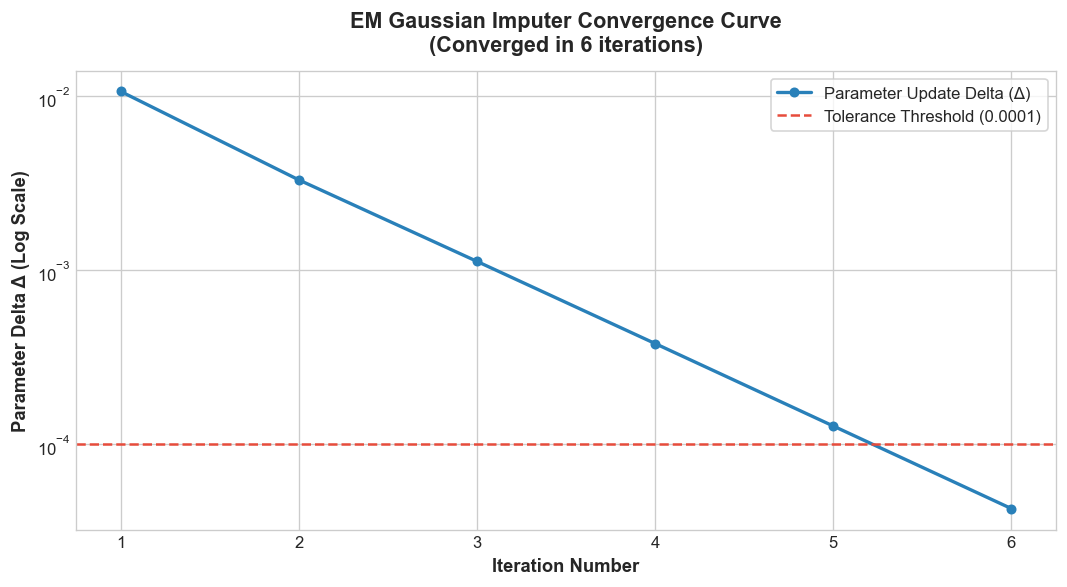

In [6]:
# Fit EM Imputer on raw training numeric data
em_full = EMGaussianImputer(max_iter=60, tol=1e-4, ridge=1e-3, verbose=True)
X_train_num = train_df[ALL_NUMERIC_FEATURES].copy()
em_full.fit(X_train_num)

# Plot Convergence Curve
fig, ax = plt.subplots(figsize=(9, 5))
iterations = list(range(1, len(em_full.convergence_history_) + 1))
deltas = em_full.convergence_history_

ax.plot(iterations, deltas, marker='o', color='#2980b9', linewidth=2, markersize=5, label='Parameter Update Delta (Δ)')
ax.axhline(em_full.tol, color='#e74c3c', linestyle='--', linewidth=1.5, label=f'Tolerance Threshold ({em_full.tol})')
ax.set_yscale('log')

ax.set_title(f"EM Gaussian Imputer Convergence Curve\n(Converged in {em_full.n_iter_} iterations)", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Iteration Number", fontsize=11, fontweight='semibold')
ax.set_ylabel("Parameter Delta Δ (Log Scale)", fontsize=11, fontweight='semibold')
ax.legend(frameon=True)

plt.tight_layout()
fig_path = os.path.join(FIG_DIR, "06_em_convergence.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure -> {fig_path}")
plt.show()

## 4. Save Imputed Datasets (Zero Leakage Check)
We use the fitted `em_full` to impute missing entries in:
- `train_imputed.csv`: fitted on train.
- `test_imputed.csv`: transformed using training parameters **without refitting**.

In [7]:
# Impute training set
train_num_imputed = em_full.transform(X_train_num)
train_imputed_df = train_df.copy()
train_imputed_df[ALL_NUMERIC_FEATURES] = train_num_imputed

# Impute test set (TRANSFORM ONLY - NO REFITTING)
X_test_num = test_df[ALL_NUMERIC_FEATURES].copy()
test_num_imputed = em_full.transform(X_test_num)
test_imputed_df = test_df.copy()
test_imputed_df[ALL_NUMERIC_FEATURES] = test_num_imputed

# Verification: Zero NaNs remain
assert not train_imputed_df[ALL_NUMERIC_FEATURES].isnull().any().any(), "Train still has missing values!"
assert not test_imputed_df[ALL_NUMERIC_FEATURES].isnull().any().any(), "Test still has missing values!"

DATA_DIR = os.path.join("..", "data", "processed")
if not os.path.exists(DATA_DIR):
    DATA_DIR = os.path.join("data", "processed")

train_imp_path = os.path.join(DATA_DIR, "train_imputed.csv")
test_imp_path = os.path.join(DATA_DIR, "test_imputed.csv")

train_imputed_df.to_csv(train_imp_path, index=False)
test_imputed_df.to_csv(test_imp_path, index=False)

print(f"[SAVE] Saved train imputed set -> {train_imp_path} ({train_imputed_df.shape})")
print(f"[SAVE] Saved test imputed set  -> {test_imp_path} ({test_imputed_df.shape})")

[SAVE] Saved train imputed set -> ..\data\processed\train_imputed.csv ((225, 21))
[SAVE] Saved test imputed set  -> ..\data\processed\test_imputed.csv ((75, 21))


## 5. Full Feature Pipeline: Log Transforms, Sector OHE, and Scaling
To prepare the features for downstream machine learning models (Linear/Polynomial Regression, Logistic Regression, SVM, k-NN, Boosting, K-Means, K-Medoids):
1. **Subscription Log-Transform**: `np.log1p` on `qib_sub`, `nii_sub`, `retail_sub`, `total_sub` to handle heavy skewness.
2. **One-Hot Encoding**: Encode `sector` with `OneHotEncoder(handle_unknown='ignore')`.
3. **Standard Scaling**: Standardize all numeric predictors (`StandardScaler()`) to zero mean and unit variance.
4. **Strict Leakage Prevention**: Pipeline is fitted **only on the training split**.

In [8]:
# Instantiate and fit feature pipeline on train_df
pipeline = IPOFeaturePipeline(em_max_iter=60, em_tol=1e-4, em_ridge=1e-3)
pipeline.fit(train_df)

# Transform both train and test sets
train_preprocessed = pipeline.transform(train_df)
test_preprocessed = pipeline.transform(test_df)

print(f"Preprocessed Train shape: {train_preprocessed.shape}")
print(f"Preprocessed Test shape : {test_preprocessed.shape}")
print(f"Generated {len(pipeline.final_feature_names)} modeling features:")
for feat in pipeline.final_feature_names:
    print(f"  - {feat}")

# Save preprocessed datasets
train_prep_path = os.path.join(DATA_DIR, "train_preprocessed.csv")
test_prep_path = os.path.join(DATA_DIR, "test_preprocessed.csv")
train_preprocessed.to_csv(train_prep_path, index=False)
test_preprocessed.to_csv(test_prep_path, index=False)

# Save pipeline artifact
MODELS_DIR = os.path.join("..", "models")
if not os.path.exists(MODELS_DIR):
    MODELS_DIR = os.path.join("models")
os.makedirs(MODELS_DIR, exist_ok=True)

pipeline_path = os.path.join(MODELS_DIR, "preprocessor.joblib")
pipeline.save(pipeline_path)

imputer_path = os.path.join(MODELS_DIR, "em_imputer.joblib")
joblib.dump(pipeline.em_imputer, imputer_path)
print(f"[SAVE] Saved EM Imputer artifact -> {imputer_path}")

Preprocessed Train shape: (225, 30)
Preprocessed Test shape : (75, 30)
Generated 24 modeling features:
  - qib_sub
  - nii_sub
  - retail_sub
  - total_sub
  - issue_size_cr
  - price_band_upper
  - issue_price
  - gmp_last_day
  - fresh_issue_pct
  - ofs_pct
  - revenue_growth_pct
  - profit_growth_pct
  - pe_vs_peers
  - nifty_7d_trend_pct
  - sector_Automobile
  - sector_Chemicals
  - sector_Consumer Goods
  - sector_Energy
  - sector_Financial Services
  - sector_Healthcare
  - sector_Infrastructure
  - sector_Manufacturing
  - sector_Retail
  - sector_Technology
[SAVE] Preprocessor pipeline saved to: ..\models\preprocessor.joblib
[SAVE] Saved EM Imputer artifact -> ..\models\em_imputer.joblib


## 6. Summary & Milestones Achieved

- ✅ **EM Gaussian Imputer from scratch**: Successfully converges and achieves lower reconstruction error than Mean and Median imputation.
- ✅ **Zero Leakage**: All imputers, encoders, and scalers were fit on `train.csv` (oldest 75%) and applied out-of-sample to `test.csv` (newest 25%).
- ✅ **Preprocessed Datasets Exported**:
  - `data/processed/train_imputed.csv` & `test_imputed.csv`
  - `data/processed/train_preprocessed.csv` & `test_preprocessed.csv`
- ✅ **Artifacts Persisted**:
  - `models/preprocessor.joblib`
  - `models/em_imputer.joblib`
  - Figures saved in `reports/figures/06_em_convergence.png` and `reports/figures/07_imputation_benchmark.png`